In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

# Load saved feature dataset
data = np.load("spectrum_sensing_features.npz")

X = data["X"]
y = data["y"]
snr = data["snr"]

feature_names = data["feature_names"]

print("Dataset loaded successfully!")
print("Features:", X.shape)
print("Labels:", y.shape)
print("SNR metadata:", snr.shape)
print("Number of features:", len(feature_names))

Dataset loaded successfully!
Features: (14000, 13)
Labels: (14000,)
SNR metadata: (14000,)
Number of features: 13


In [2]:
print("Missing values:", np.isnan(X).sum())
print("Infinite values:", np.isinf(X).sum())

print("\nClass distribution:")
print(pd.Series(y).value_counts())

print("\nSNR levels:")
print(np.unique(snr))

Missing values: 0
Infinite values: 0

Class distribution:
0    7000
1    7000
Name: count, dtype: int64

SNR levels:
[-20 -15 -10  -5   0   5  10]


In [3]:
# Create combined stratification groups
stratify_groups = np.array([
    f"{label}_{snr_value}"
    for label, snr_value in zip(y, snr)
])

# First split: 70% training, 30% temporary
X_train, X_temp, y_train, y_temp, snr_train, snr_temp = (
    train_test_split(
        X, y, snr,
        test_size=0.30,
        random_state=42,
        stratify=stratify_groups
    )
)

# Second split: 15% validation, 15% testing
temp_stratify = np.array([
    f"{label}_{snr_value}"
    for label, snr_value in zip(y_temp, snr_temp)
])

X_val, X_test, y_val, y_test, snr_val, snr_test = (
    train_test_split(
        X_temp, y_temp, snr_temp,
        test_size=0.50,
        random_state=42,
        stratify=temp_stratify
    )
)

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Testing set:", X_test.shape)

Training set: (9800, 13)
Validation set: (2100, 13)
Testing set: (2100, 13)


In [4]:
from sklearn.preprocessing import StandardScaler

print("StandardScaler imported successfully!")

StandardScaler imported successfully!


In [5]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

print("Training data scaled successfully!")

Training data scaled successfully!


In [6]:
X_val_scaled = scaler.transform(X_val)

X_test_scaled = scaler.transform(X_test)

print("Validation and testing data scaled successfully!")

Validation and testing data scaled successfully!


In [7]:
print("Training feature means:")
print(np.round(X_train_scaled.mean(axis=0), 4))

print("\nTraining feature standard deviations:")
print(np.round(X_train_scaled.std(axis=0), 4))

Training feature means:
[ 0.  0. -0.  0. -0. -0.  0.  0. -0. -0. -0.  0.  0.]

Training feature standard deviations:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [8]:
print("Training:", X_train_scaled.shape)
print("Validation:", X_val_scaled.shape)
print("Testing:", X_test_scaled.shape)

Training: (9800, 13)
Validation: (2100, 13)
Testing: (2100, 13)


In [10]:
raw_data = np.load("spectrum_sensing_dataset.npz")

X_iq = raw_data["X"]

print("IQ dataset shape:", X_iq.shape)

IQ dataset shape: (14000, 256)


In [11]:
indices = np.arange(len(y))

train_idx, temp_idx = train_test_split(
    indices,
    test_size=0.30,
    random_state=42,
    stratify=np.array([
        f"{label}_{s}"
        for label, s in zip(y, snr)
    ])
)

temp_groups = np.array([
    f"{y[i]}_{snr[i]}"
    for i in temp_idx
])

val_idx, test_idx = train_test_split(
    temp_idx,
    test_size=0.50,
    random_state=42,
    stratify=temp_groups
)

print("Train indices:", len(train_idx))
print("Validation indices:", len(val_idx))
print("Test indices:", len(test_idx))

Train indices: 9800
Validation indices: 2100
Test indices: 2100


In [12]:
energy_train = np.mean(
    np.abs(X_iq[train_idx])**2,
    axis=1
)

energy_val = np.mean(
    np.abs(X_iq[val_idx])**2,
    axis=1
)

energy_test = np.mean(
    np.abs(X_iq[test_idx])**2,
    axis=1
)

print("Energy extraction completed!")
print("Training:", energy_train.shape)
print("Validation:", energy_val.shape)
print("Testing:", energy_test.shape)

Energy extraction completed!
Training: (9800,)
Validation: (2100,)
Testing: (2100,)


In [13]:
target_pfa = 0.05

print("Target False Alarm Probability:", target_pfa)

Target False Alarm Probability: 0.05


In [14]:
energy_thresholds = {}

for s in np.unique(snr):

    # Select H0 validation observations at this SNR
    mask = (snr[val_idx] == s) & (y[val_idx] == 0)

    h0_val_energy = energy_val[mask]

    # Set threshold at the 95th percentile
    threshold = np.quantile(
        h0_val_energy,
        1 - target_pfa,
        method="higher"
    )

    energy_thresholds[s] = threshold

print("Energy detection thresholds:\n")

for s, threshold in energy_thresholds.items():
    print(f"SNR: {s:>3} dB | Threshold: {threshold:.6f}")

Energy detection thresholds:

SNR: -20 dB | Threshold: 110.342552
SNR: -15 dB | Threshold: 34.307513
SNR: -10 dB | Threshold: 11.108867
SNR:  -5 dB | Threshold: 3.471451
SNR:   0 dB | Threshold: 1.111443
SNR:   5 dB | Threshold: 0.354572
SNR:  10 dB | Threshold: 0.110712


In [15]:
print("Validation False Alarm Probability:\n")

for s, threshold in energy_thresholds.items():

    mask = (
        (snr[val_idx] == s) &
        (y[val_idx] == 0)
    )

    h0_energy = energy_val[mask]

    pfa = np.mean(h0_energy > threshold)

    print(f"SNR: {s:>3} dB | Pfa: {pfa:.4f}")

Validation False Alarm Probability:

SNR: -20 dB | Pfa: 0.0467
SNR: -15 dB | Pfa: 0.0467
SNR: -10 dB | Pfa: 0.0467
SNR:  -5 dB | Pfa: 0.0467
SNR:   0 dB | Pfa: 0.0467
SNR:   5 dB | Pfa: 0.0467
SNR:  10 dB | Pfa: 0.0467


In [16]:
from sklearn.metrics import confusion_matrix

ed_results = []

for s, threshold in energy_thresholds.items():

    # Select test observations for this SNR
    mask = snr[test_idx] == s

    true_labels = y[test_idx][mask]
    measured_energy = energy_test[mask]

    # Energy detector predictions
    predictions = (
        measured_energy > threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        true_labels,
        predictions,
        labels=[0, 1]
    ).ravel()

    pd_value = tp / (tp + fn)
    pfa_value = fp / (fp + tn)
    pm_value = fn / (fn + tp)

    ed_results.append({
        "SNR": s,
        "Pd": pd_value,
        "Pfa": pfa_value,
        "Pm": pm_value
    })

ed_df = pd.DataFrame(ed_results)

print(ed_df.round(4))

   SNR      Pd     Pfa      Pm
0  -20  0.0467  0.0800  0.9533
1  -15  0.1867  0.0733  0.8133
2  -10  0.3867  0.0733  0.6133
3   -5  1.0000  0.0467  0.0000
4    0  1.0000  0.0267  0.0000
5    5  1.0000  0.0267  0.0000
6   10  1.0000  0.0600  0.0000


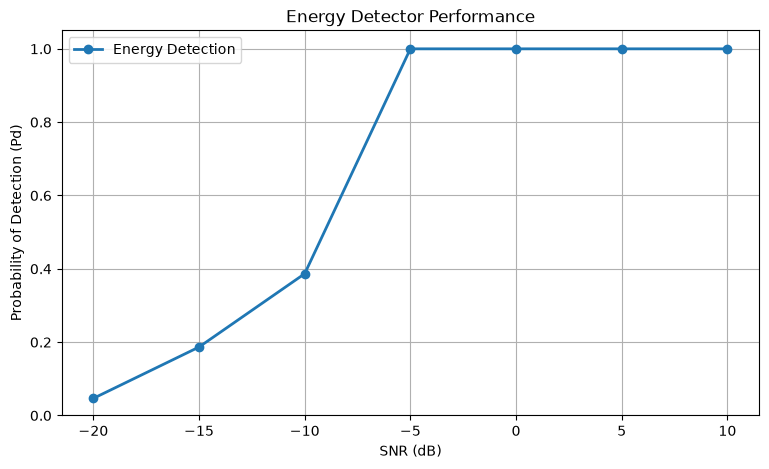

In [18]:
plt.figure(figsize=(9, 5))

plt.plot(
    ed_df["SNR"],
    ed_df["Pd"],
    marker="o",
    linewidth=2,
    label="Energy Detection"
)

plt.xlabel("SNR (dB)")
plt.ylabel("Probability of Detection (Pd)")
plt.title("Energy Detector Performance")
plt.ylim(0, 1.05)
plt.xticks(np.unique(snr))
plt.grid(True)
plt.legend()

plt.show()

In [19]:
ed_df.to_csv(
    "energy_detector_results.csv",
    index=False
)

print("Energy Detector results saved successfully!")

Energy Detector results saved successfully!


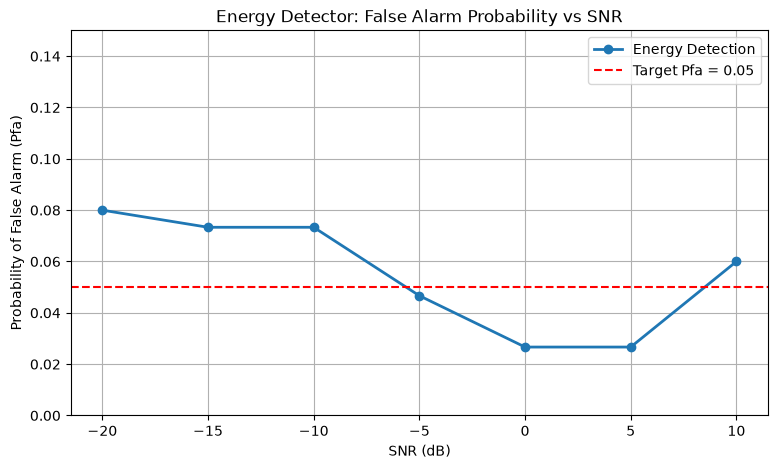

In [20]:
plt.figure(figsize=(9, 5))

plt.plot(
    ed_df["SNR"],
    ed_df["Pfa"],
    marker="o",
    linewidth=2,
    label="Energy Detection"
)

# Target false alarm probability
plt.axhline(
    y=0.05,
    color="red",
    linestyle="--",
    label="Target Pfa = 0.05"
)

plt.xlabel("SNR (dB)")
plt.ylabel("Probability of False Alarm (Pfa)")
plt.title("Energy Detector: False Alarm Probability vs SNR")

plt.xticks(np.unique(snr))
plt.ylim(0, 0.15)
plt.grid(True)
plt.legend()

plt.show()